# Cell Type Counts and Proportions

This notebook reads two `.h5ad` datasets and creates, for each dataset:
1. Absolute cell counts per `cell_type`
2. Cell type proportions
3. A CSV table with cell counts and percentages per `cell_type`

Set dataset paths in the configuration cell below.


In [1]:
from pathlib import Path

import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")


In [37]:
# Set your input paths here
H5AD_PATH_1 = "/Users/<user>/Documents/Arbeit/Projects/Single_Cell_Foundation_Models/sc_language_foundation_models/cache/human_pancreas_sub2000.h5ad"
H5AD_PATH_2 = "/Users/<user>/Documents/Arbeit/Projects/Single_Cell_Foundation_Models/sc_language_foundation_models/cache/Zeisel_sub2000.h5ad"
PLOT_OUTPUT_DIR = "notebook_outputs"

dataset_paths = [H5AD_PATH_1.strip(), H5AD_PATH_2.strip()]

if any(not p for p in dataset_paths):
    raise ValueError("Please set both H5AD_PATH_1 and H5AD_PATH_2 in the config cell.")

for dataset_path in dataset_paths:
    if not Path(dataset_path).exists():
        raise FileNotFoundError(f"Dataset not found: {dataset_path}")

plot_output_dir = Path(PLOT_OUTPUT_DIR).expanduser()
plot_output_dir.mkdir(parents=True, exist_ok=True)

dataset_paths


['/Users/<user>/Documents/Arbeit/Projects/Single_Cell_Foundation_Models/sc_language_foundation_models/cache/human_pancreas_sub2000.h5ad',
 '/Users/<user>/Documents/Arbeit/Projects/Single_Cell_Foundation_Models/sc_language_foundation_models/cache/Zeisel_sub2000.h5ad']

In [32]:
def get_cell_type_counts(adata: sc.AnnData) -> pd.Series:
    cell_type_key = "cell_type"
    if cell_type_key not in adata.obs.columns:
        cell_type_key = "TaxonomyRank4"
        if cell_type_key not in adata.obs.columns:
            cell_type_key = "celltype"
            if cell_type_key not in adata.obs.columns:
                raise KeyError(
                    "Missing `cell_type` column in `adata.obs`. "
                    f"Available columns: {list(adata.obs.columns)}"
                )
    return adata.obs[cell_type_key].astype(str).value_counts().sort_values(ascending=False)


def build_summary_table(counts: pd.Series) -> pd.DataFrame:
    summary = counts.rename_axis("cell_type").reset_index(name="cell_count")
    summary["cell_percentage"] = (summary["cell_count"] / summary["cell_count"].sum()) * 100
    summary["cell_percentage"] = summary["cell_percentage"].round(4)
    return summary


def save_summary_table(dataset_name: str, summary: pd.DataFrame, output_dir: Path) -> None:
    out_path = output_dir / f"{dataset_name}_cell_type_summary.csv"
    summary.to_csv(out_path, index=False)
    print(f"Saved: {out_path}")


def plot_counts(dataset_name: str, counts: pd.Series, output_dir: Path) -> None:
    fig_height = max(4, len(counts) * 0.3)
    fig, ax = plt.subplots(figsize=(12, fig_height))
    counts.sort_values(ascending=True).plot(kind="barh", ax=ax, color="#1f77b4")
    ax.set_title(f"{dataset_name}: Absolute Cell Counts by Cell Type")
    ax.set_xlabel("Cell count")
    ax.set_ylabel("Cell type")
    fig.tight_layout()
    out_path = output_dir / f"{dataset_name}_cell_type_absolute_counts.png"
    fig.savefig(out_path, dpi=200)
    plt.show()
    plt.close(fig)
    print(f"Saved: {out_path}")


def plot_proportions(dataset_name: str, proportions: pd.Series, output_dir: Path) -> None:
    fig_height = max(4, len(proportions) * 0.3)
    fig, ax = plt.subplots(figsize=(12, fig_height))
    proportions.sort_values(ascending=True).plot(kind="barh", ax=ax, color="#ff7f0e")
    ax.set_title(f"{dataset_name}: Cell Type Proportions")
    ax.set_xlabel("Proportion of cells")
    ax.set_ylabel("Cell type")
    ax.set_xlim(0, 1)
    fig.tight_layout()
    out_path = output_dir / f"{dataset_name}_cell_type_proportions.png"
    fig.savefig(out_path, dpi=200)
    plt.show()
    plt.close(fig)
    print(f"Saved: {out_path}")



Processing: /Users/<user>/Documents/Arbeit/Projects/Single_Cell_Foundation_Models/sc_language_foundation_models/cache/human_pancreas_sub2000.h5ad


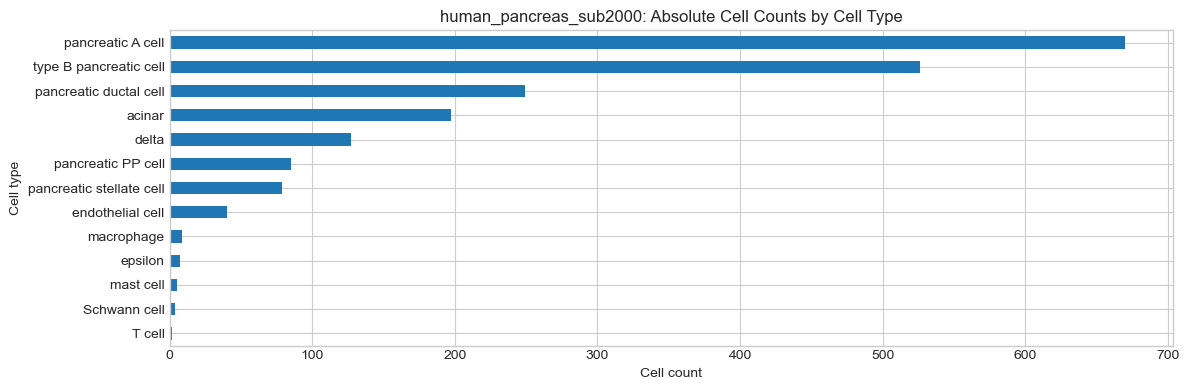

Saved: notebook_outputs/human_pancreas_sub2000_cell_type_absolute_counts.png


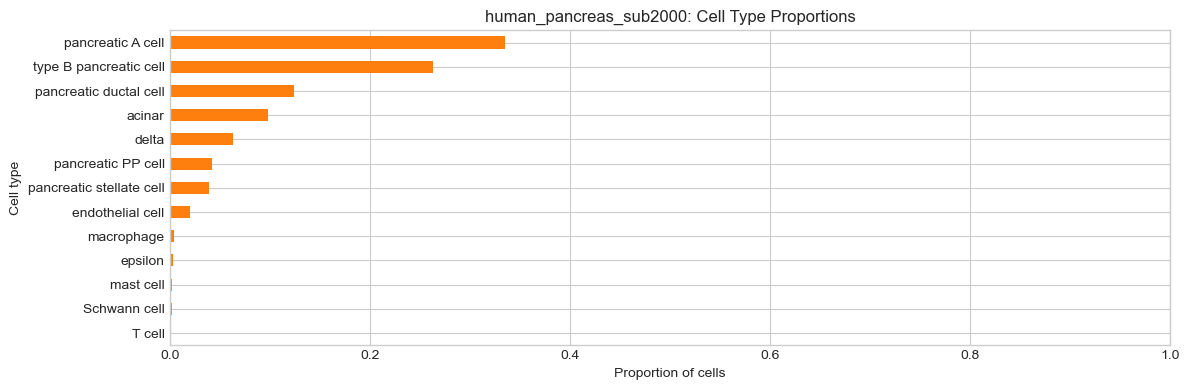

Saved: notebook_outputs/human_pancreas_sub2000_cell_type_proportions.png
Saved: notebook_outputs/human_pancreas_sub2000_cell_type_summary.csv


,cell_type,cell_count,cell_percentage
0,pancreatic A cell,670,33.50
1,type B pancreatic cell,526,26.30
2,pancreatic ductal cell,249,12.45
3,acinar,197,9.85
4,delta,127,6.35
5,pancreatic PP cell,85,4.25
6,pancreatic stellate cell,79,3.95
7,endothelial cell,40,2.00
8,macrophage,9,0.45
9,epsilon,7,0.35



Processing: /Users/<user>/Documents/Arbeit/Projects/Single_Cell_Foundation_Models/sc_language_foundation_models/cache/Zeisel_sub2000.h5ad


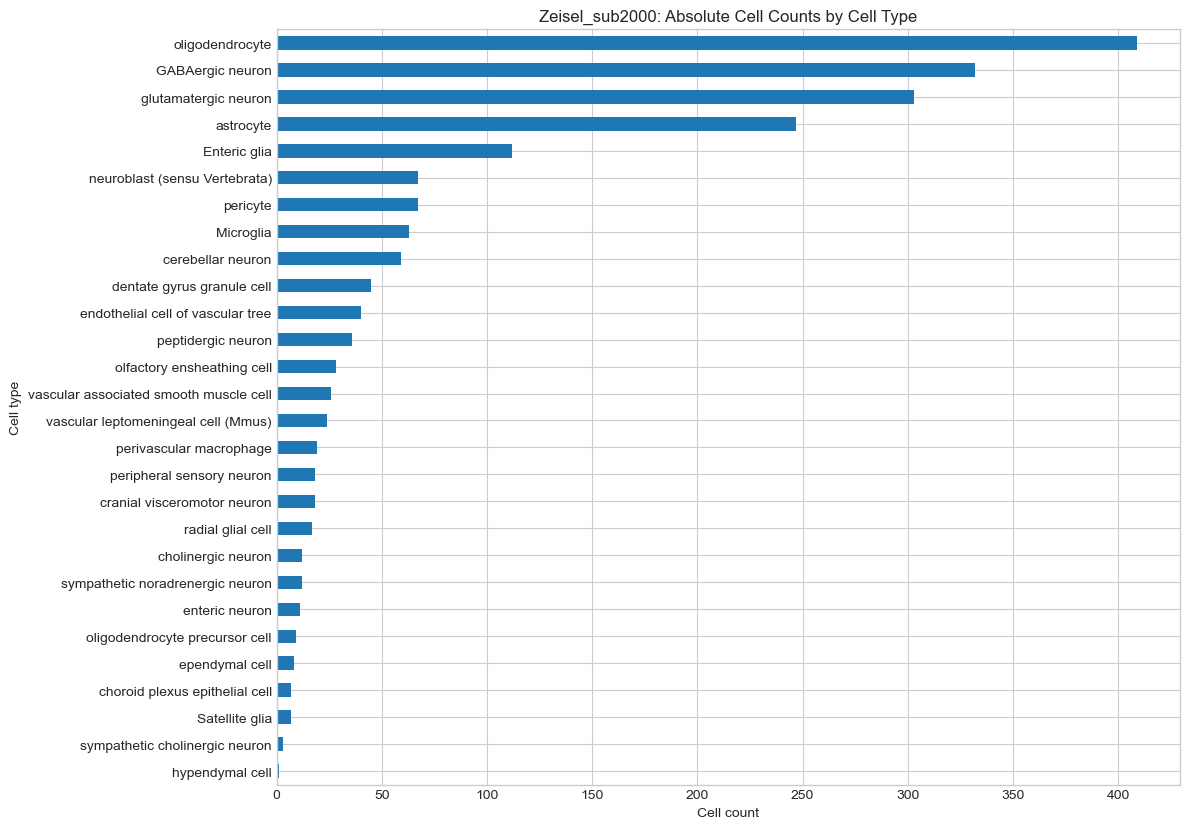

Saved: notebook_outputs/Zeisel_sub2000_cell_type_absolute_counts.png


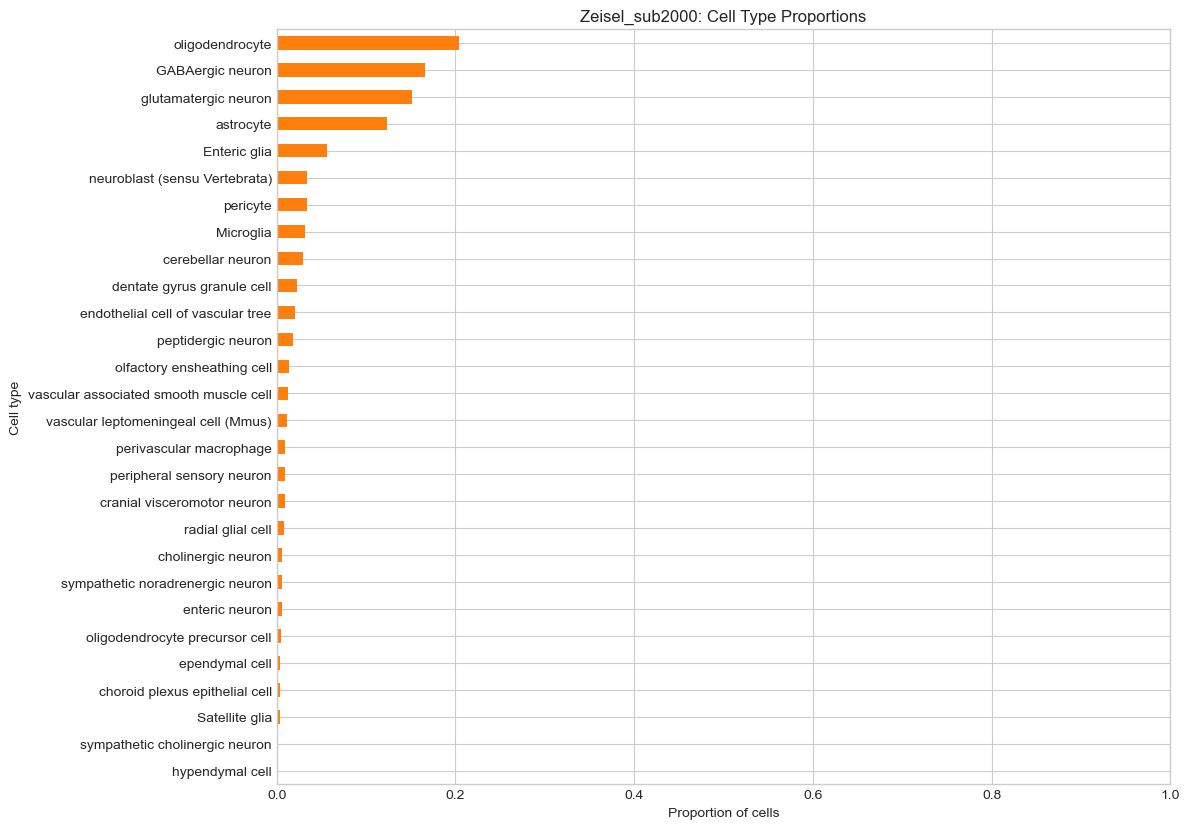

Saved: notebook_outputs/Zeisel_sub2000_cell_type_proportions.png
Saved: notebook_outputs/Zeisel_sub2000_cell_type_summary.csv


,cell_type,cell_count,cell_percentage
0,oligodendrocyte,409,20.45
1,GABAergic neuron,332,16.60
2,glutamatergic neuron,303,15.15
3,astrocyte,247,12.35
4,Enteric glia,112,5.60
5,neuroblast (sensu Vertebrata),67,3.35
6,pericyte,67,3.35
7,Microglia,63,3.15
8,cerebellar neuron,59,2.95
9,dentate gyrus granule cell,45,2.25


In [38]:
for dataset_path in dataset_paths:
    dataset_file = Path(dataset_path)
    dataset_name = dataset_file.stem
    print(f"\nProcessing: {dataset_file}")

    adata = sc.read_h5ad(dataset_file)
    counts = get_cell_type_counts(adata)
    proportions = counts / counts.sum()
    summary_table = build_summary_table(counts)

    plot_counts(dataset_name=dataset_name, counts=counts, output_dir=plot_output_dir)
    plot_proportions(
        dataset_name=dataset_name, proportions=proportions, output_dir=plot_output_dir
    )
    save_summary_table(dataset_name=dataset_name, summary=summary_table, output_dir=plot_output_dir)

    display(summary_table)


In [34]:
sc.read_h5ad(H5AD_PATH_2) #H5AD_PATH_1 #H5AD_PATH_2
adata

AnnData object with n_obs × n_vars = 16382 × 19093
    obs: 'tech', 'celltype', 'size_factors', 'original_celltype'
    layers: 'counts'

In [26]:
adata.obs.TaxonomyRank4.unique()

['Enteric neurons', 'Enteric glia', 'Oligodendrocytes', 'Cholinergic and monoaminergic neurons', 'Telencephalon projecting excitatory neurons', ..., 'Sympathetic noradrenergic neurons', 'Sympathetic cholinergic neurons', 'Peripheral sensory peptidergic neurons', 'Peripheral sensory neurofilament neurons', 'Peripheral sensory non-peptidergic neurons']
Length: 39
Categories (39, str): ['Astrocytes', 'Cerebellum neurons', 'Cholinergic and monoaminergic neurons', 'Choroid epithelial cells', ..., 'Telencephalon projecting inhibitory neurons', 'Vascular and leptomeningeal cells', 'Vascular endothelial cells', 'Vascular smooth muscle cells']

In [24]:
adata.obs.TaxonomyRank4.unique()

['Enteric neurons', 'Enteric glia', 'Oligodendrocytes', 'Cholinergic and monoaminergic neurons', 'Telencephalon projecting excitatory neurons', ..., 'Sympathetic noradrenergic neurons', 'Sympathetic cholinergic neurons', 'Peripheral sensory peptidergic neurons', 'Peripheral sensory neurofilament neurons', 'Peripheral sensory non-peptidergic neurons']
Length: 39
Categories (39, str): ['Astrocytes', 'Cerebellum neurons', 'Cholinergic and monoaminergic neurons', 'Choroid epithelial cells', ..., 'Telencephalon projecting inhibitory neurons', 'Vascular and leptomeningeal cells', 'Vascular endothelial cells', 'Vascular smooth muscle cells']